# Flow matching with transformer
This tutorial is part of the talk on the TUPHEDS Group Meeting on 28.10.2026.

- The flow-matching part is based on the [flow-matching notebook](https://github.com/lukasheinrich/generative_models_examples/blob/main/flowmatching/FlowMatching2D.ipynb) by Lukas Heinrich.
- The transformer part is based on the [GPT tutorial](https://www.youtube.com/watch?v=kCc8FmEb1nY) by Andrej Karpathy.
- Many ideas were learnt from the [codebase](https://github.com/lego-erc/FM-Transformer/tree/main) of Richard Hildebrandt.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint
import sklearn.datasets as skld
import torch
import torch.nn as nn
from torch.nn import functional as F

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


We start by constructing: 

- the conditional velocity field $u_t(x \mid x_1)
= \frac{x_1 - (1 - \sigma_{\min})x}
{1 - (1 - \sigma_{\min})t}$
- the conditional flow $\psi_t(x \mid x_1)
= \left(1 - (1 - \sigma_{\min})t\right)x + tx_1$

We will test our model on the two-moons dataset

In [25]:
Sigmin_2d = torch.tensor([0.01, 0.01], device=device)

# get conditional velocity field u_t(x|x_1)
def conditional_field(position, time, target, sigmin):
    return (target-(1-sigmin)*position)/(1-(1-sigmin)*time)

# get conditional flow psi_t(x)
def conditional_sample(noise, time, target, sigmin):
    sigma = 1-(1-sigmin)*time
    mean = time*target
    return sigma*noise + mean

def sample_data_2d(N=100):
    return torch.tensor(skld.make_moons(N)[0], dtype=torch.float32, device=device)

The mask will be randomly chosen in the training.

In [26]:
masks = torch.tensor([
    [True, False], # first var known, second var unknown
    [False, True],
    [False, False], # both variables unknown
], device=device)

In [59]:
# hyperparameters
batch_size = 1000
learning_rate = 1e-3
max_iters = 10000
eval_interval = 500
n_embd = 64
n_heads = 4
n_layers = 4
dropout = 0
# ------------

### Let's first build one from scratch!

#### Self-Attention and Transformer Building Blocks (Nothing New)

In [56]:
class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        k = self.key(x)   # (B,T,H), H = head_size
        q = self.query(x) # (B,T,H)
        B,T,head_size = k.shape
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * head_size**-0.5 # (B, T, H) @ (B, H, T) -> (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,H)
        out = wei @ v # (B, T, T) @ (B, T, H) -> (B, T, H)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedForward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

#### Flow-Matching Encoder Transformer
Here we come to the core of the tutorial.
We choose an encoder transformer, because our model uses non-casual attention

In [10]:
class Encoder_Transformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Linear(1, n_embd) # Since input is continuous, we use nn.Linear() instead of nn.Embedding()
        self.variable_embedding = nn.Embedding(3, n_embd) # Type of the token, (data[0], data[1], time)
        self.known_embedding = nn.Embedding(2, n_embd) # The flow should act different to the token, depending on if it's known
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_heads) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.vf_head = nn.Linear(n_embd, 1) # from embedding to velocity field

    def forward(self, idx, known=None):
        '''
        idx: (B, 3), Input[0] = [data[0], data[1], time]
        known: (2,) or (B, 2), List or torch.tensor, dtype = torch.bool
        '''
        B, T = idx.shape

        if known is None:
            known = torch.zeros((B, 2), dtype=torch.bool, device=device)
        else:
            known = torch.as_tensor(known, dtype=torch.bool, device=device)
            if known.ndim == 1:
                known = known.expand(B, -1)
        
        # B = batch_size, T = dim_input, C = embedding_dimension
        tok_emb = self.token_embedding(idx.unsqueeze(-1)) # (B,T,C)
        var_emb = self.variable_embedding(torch.arange(T, device=device)) # (T,C)

        # Append True for time dimension
        known_full = torch.cat([known, known.new_ones((B, 1))], dim=1)  # (B,T)
        kno_emb = self.known_embedding(known_full.long())  # (B,T,C)

        x = tok_emb + var_emb + kno_emb
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)

        logits = self.vf_head(x).squeeze(-1)[:, :-1]  # (B,2)
        logits = logits * (~known)

        return logits


#### Flow-Matching Training

In [61]:
def train_transformer_FM(model):
    opt = torch.optim.Adam(model.parameters(), learning_rate)

    for i in range(max_iters):

        # sample noise, target, times and indices
        noise = torch.randn(batch_size, 2, device=device)
        target = sample_data_2d(batch_size)
        times = torch.rand(batch_size, 1, device=device)
        indices = torch.randint(len(masks), (batch_size,), device=device)


        known_masks = masks[indices]
        positions = conditional_sample(noise, times, target, Sigmin_2d) # calculate cond flow at given times
        cond_field = conditional_field(positions, times, target, Sigmin_2d) # calculate cond VF for loss function
        positions = torch.where(known_masks, target, positions) # The input contains noise for unknown var and target for known var

        xt = torch.column_stack([positions, times])
        model_field = model(xt, known=known_masks)

        unknown = ~known_masks
        loss = ((model_field - cond_field)**2 * unknown).sum() / unknown.sum() # The loss is a weighted loss conbining all three masks
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % eval_interval == 0 or i == max_iters - 1:
            print(f"step {i}: train loss {loss:.4f}")
    return model


In [62]:
vf = Encoder_Transformer()
vf = vf.to(device)

vf = train_transformer_FM(vf)

step 0: train loss 1.3749
step 500: train loss 0.7953
step 1000: train loss 0.6831
step 1500: train loss 0.7383
step 2000: train loss 0.7431
step 2500: train loss 0.7339
step 3000: train loss 0.7921
step 3500: train loss 0.7813
step 4000: train loss 0.6780
step 4500: train loss 0.7610
step 5000: train loss 0.7335
step 5500: train loss 0.7331
step 6000: train loss 0.7361
step 6500: train loss 0.7288
step 7000: train loss 0.7426
step 7500: train loss 0.7094
step 8000: train loss 0.8234
step 8500: train loss 0.6925
step 9000: train loss 0.6985
step 9500: train loss 0.6759
step 9999: train loss 0.7066


#### Evaluation


##### Generate both coordinates

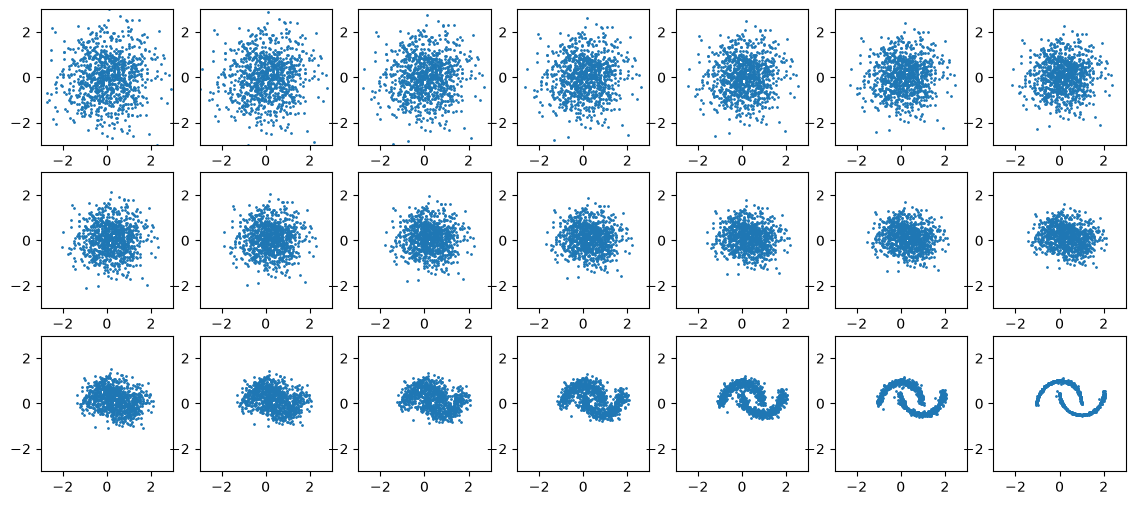

In [63]:
vf.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21, device=device)
    xint = odeint(lambda t, x:vf(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1)),
                torch.randn(1000,2, device=device), tint)
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

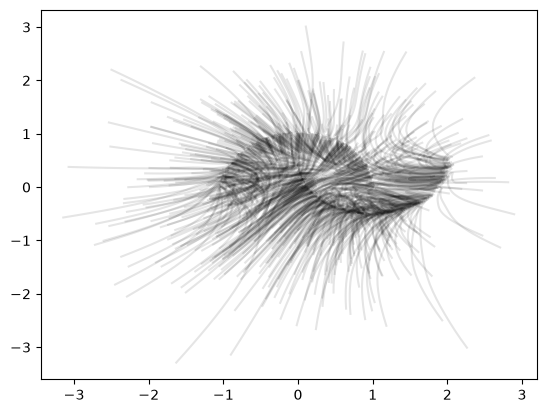

In [64]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()

##### How about conditional generation?

/tmp/ipykernel_2313579/3113254068.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  positions, torch.tensor(tint, device=device))


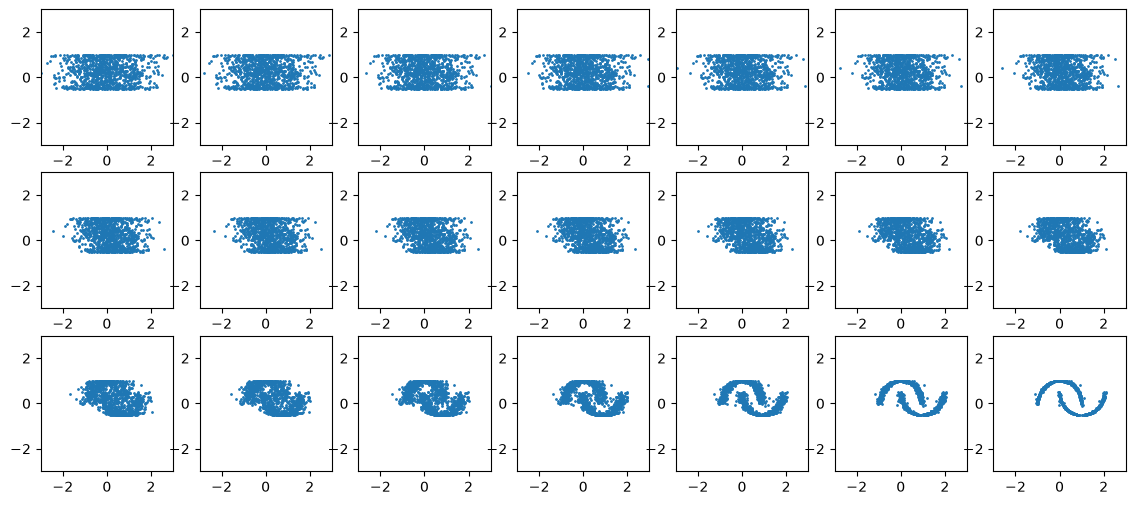

In [65]:
vf.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21)
    known = [False, True] # provide a mask
    target = sample_data_2d(1000)[:,1].unsqueeze(-1)
    positions = torch.cat([torch.randn(1000,1, device=device),target],dim=-1)
    xint = odeint(lambda t, x:vf(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1), known=known),
                positions, torch.tensor(tint, device=device))
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

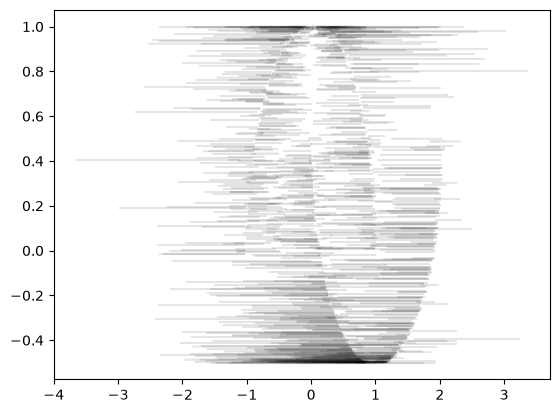

In [66]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()

/tmp/ipykernel_2313579/1667773398.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  positions, torch.tensor(tint, device=device))


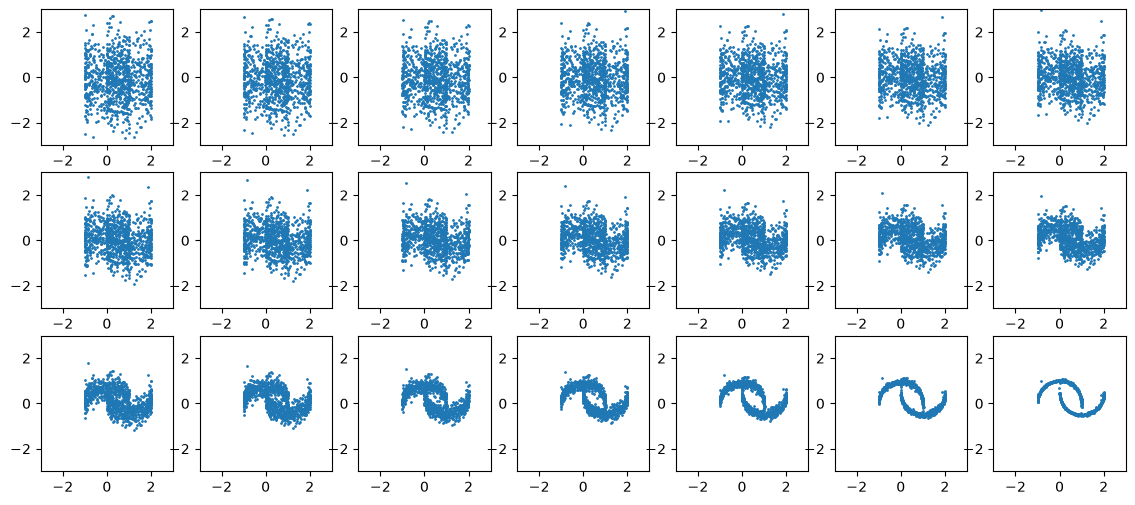

In [67]:
vf.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21)
    known = [True, False]
    target = sample_data_2d(1000)[:,0].unsqueeze(-1)
    positions = torch.cat([target,torch.randn(1000,1, device=device)],dim=-1)
    xint = odeint(lambda t, x:vf(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1), known=known),
                positions, torch.tensor(tint, device=device))
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

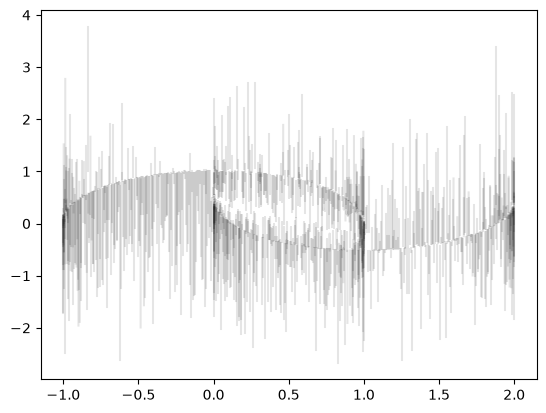

In [68]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()

### The following is an example of the same setup using packages
 x-transformer & flow-matching packages

In [ ]:
!pip install x_transformers
!pip install flow_matching 

In [ ]:
from flow_matching.path.scheduler import CondOTScheduler
from flow_matching.path import AffineProbPath
from flow_matching.solver import ODESolver
from flow_matching.utils import ModelWrapper

from x_transformers import ContinuousTransformerWrapper, Encoder

/scratch/users/yinya/.venv/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
# hyperparameters
batch_size = 1000
learning_rate = 1e-3
max_iters = 10000
eval_interval = 500
n_embd = 64
n_heads = 4
n_layers = 4
dropout = 0
# ------------

In [39]:
# Transformer Backbone

class Encoder_x_Transformer(nn.Module):
    def __init__(self, n_embd=n_embd, n_layers=n_layers, n_heads=4):
        super().__init__()
        self.known_embedding = nn.Embedding(2, n_embd) # This will be passed to x-transformer as sum_embeds

        self.transformer = ContinuousTransformerWrapper(
            dim_in = 1,
            dim_out = 1,
            max_seq_len = 3,
            attn_layers = Encoder(
                dim = n_embd,
                depth = n_layers,
                heads = n_heads
            )
)

    def forward(self, idx, known=None):
        '''
        idx: (B, 3), Input[0] = [data[0], data[1], time]
        known: (2,) or (B, 2), List or torch.tensor, dtype = torch.bool
        '''
        B, T = idx.shape
        assert T==3, "Number of variables must be 3"

        if known is None:
            known = torch.zeros((B, 2), dtype=torch.bool, device=device)
        else:
            known = torch.as_tensor(known, dtype=torch.bool, device=device)
            if known.ndim == 1:
                known = known.expand(B, -1)

        # Append True for time dimension
        known_full = torch.cat([known, known.new_ones((B, 1))], dim=1)  # (B,T)
        kno_emb = self.known_embedding(known_full.long())  # (B,T,C)

        velocity = self.transformer(idx.unsqueeze(-1), sum_embeds=kno_emb)
        velocity = velocity.squeeze(-1)[:, :-1]  # (B,2)

        return velocity.masked_fill(known, 0.0)

In [40]:
transformer = Encoder_x_Transformer()
transformer = transformer.to(device)

In [42]:
path = AffineProbPath(scheduler=CondOTScheduler())

In [ ]:
def train_val_loop(model):

    indices = torch.randint(len(masks), (batch_size,), device=device)
    target = sample_data_2d(batch_size)
    times = torch.rand(batch_size, 1, device=device)
    noise = torch.randn(batch_size, 2, device=device)

    known_masks = masks[indices]
    path_sample = path.sample(x_0=noise, x_1=target, t=times.squeeze(-1))
    positions = torch.where(known_masks, target, path_sample.x_t)
    xt = torch.column_stack([positions, times])
    model_field = model(xt, known=known_masks)

    unknown = ~known_masks
    loss = ((model_field - path_sample.dx_t)**2 * unknown).sum() / unknown.sum()

    return loss

def train_x_transformer_FM(model):
    opt = torch.optim.Adam(model.parameters(), learning_rate)

    loss_history = []
    for i in range(max_iters):

        loss = train_val_loop(model)
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % eval_interval == 0 or i == max_iters - 1:
            print(f"step {i}: train loss {loss:.4f}")
    return model, loss_history


vf = Encoder_x_Transformer()
vf = vf.to(device)

vf.train()
vf, loss_history = train_x_transformer_FM(vf)

step 0: train loss 1.7571, val loss 5.5371
step 50: train loss 1.3173, val loss 1.2424
step 100: train loss 1.1647, val loss 1.1304
step 150: train loss 0.9925, val loss 0.9601
step 200: train loss 1.0167, val loss 0.9085
step 250: train loss 0.8740, val loss 0.8634
step 300: train loss 0.8765, val loss 0.8428
step 350: train loss 0.9007, val loss 0.8299
step 400: train loss 0.8549, val loss 0.8234
step 450: train loss 0.8625, val loss 0.8085
step 500: train loss 0.7678, val loss 0.7759
step 550: train loss 0.8192, val loss 0.7997
step 600: train loss 0.8510, val loss 0.7702
step 650: train loss 0.8296, val loss 0.8165
step 700: train loss 0.8393, val loss 0.8017
step 750: train loss 0.7389, val loss 0.7730
step 800: train loss 0.7423, val loss 0.7408
step 850: train loss 0.8063, val loss 0.7714
step 900: train loss 0.7446, val loss 0.7546
step 950: train loss 0.8551, val loss 0.7848


##### Sampling

In [53]:
class WrappedModel(ModelWrapper):
    def forward(self, x: torch.Tensor, t: torch.Tensor, **extras):
        xt = torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1)
        return self.model(xt, **extras)

wrapped_vf = WrappedModel(vf)

In [54]:
# step size for ode solver
step_size = 0.05

model = vf.eval()

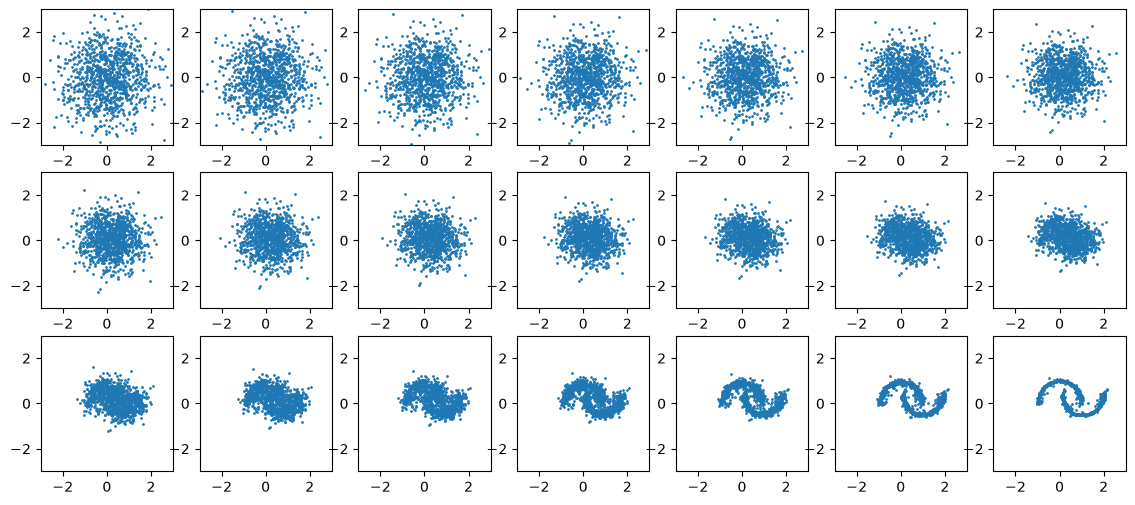

In [55]:
with torch.no_grad():
    T = torch.linspace(0.0,1.0,21, device=device)
    x_init = torch.randn(1000,2, device=device)
    solver = ODESolver(velocity_model=wrapped_vf)  # create an ODESolver class
    xint = solver.sample(time_grid=T, x_init=x_init, method='midpoint', step_size=step_size, return_intermediates=True)  # sample from the model
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

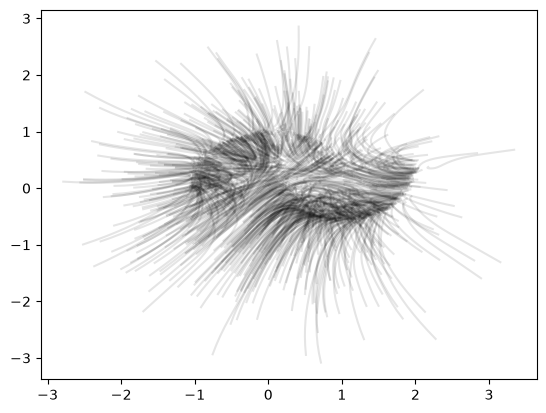

In [48]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()